In [1]:
# Step 1: Check the Python environment

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Environment check completed successfully.")

Python version: 3.12.15
Pandas version: 2.3.3
NumPy version: 2.3.5
Environment check completed successfully.


In [2]:
from pathlib import Path

# Locate the raw data folder (original file only, no checkpoints)
raw_folder = Path.cwd().parent / "RAW"
csv_files = list(raw_folder.glob("*.csv"))

print("CSV files found:", len(csv_files))
for file in csv_files:
    print("-", file.name)

# Select the original file
file_path = csv_files[0]

CSV files found: 1
- Helsinki Kaisaniemi_ 1.1.2006 - 31.12.2025_25a675ef-2d9a-43c9-88d5-c2e6395bc30b.csv


In [3]:
# Show the first 20 lines of the original file
print("Selected file:", file_path.name)
print("\nFirst 20 lines of the original CSV:\n")

with open(file_path, "r", encoding="utf-8-sig") as file:
    for i in range(20):
        line = file.readline()
        if not line:
            break
        print(line.rstrip())

Selected file: Helsinki Kaisaniemi_ 1.1.2006 - 31.12.2025_25a675ef-2d9a-43c9-88d5-c2e6395bc30b.csv

First 20 lines of the original CSV:

"Observation station","Year","Month","Day","Time [Local time]","Average temperature [°C]","Maximum temperature [°C]","Minimum temperature [°C]"
"Helsinki Kaisaniemi","2006","1","1","00:00","2","2.2","1.8"
"Helsinki Kaisaniemi","2006","1","1","01:00","1.9","2","1.7"
"Helsinki Kaisaniemi","2006","1","1","02:00","2","2.1","1.7"
"Helsinki Kaisaniemi","2006","1","1","03:00","2.1","2.2","1.1"
"Helsinki Kaisaniemi","2006","1","1","04:00","1.4","2","0.6"
"Helsinki Kaisaniemi","2006","1","1","05:00","0.6","1","0.3"
"Helsinki Kaisaniemi","2006","1","1","06:00","0.1","0.3","-0.2"
"Helsinki Kaisaniemi","2006","1","1","07:00","-0.2","-0.1","-0.3"
"Helsinki Kaisaniemi","2006","1","1","08:00","-0.4","-0.3","-0.5"
"Helsinki Kaisaniemi","2006","1","1","09:00","-0.4","-0.4","-0.5"
"Helsinki Kaisaniemi","2006","1","1","10:00","-0.5","-0.3","-0.9"
"Helsinki Kaisaniemi","

In [4]:
# Read the original FMI dataset
df = pd.read_csv(file_path, encoding="utf-8-sig", low_memory=False)

print("Dataset loaded successfully!")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Number of rows: 174998
Number of columns: 8

Column names:
['Observation station', 'Year', 'Month', 'Day', 'Time [Local time]', 'Average temperature [°C]', 'Maximum temperature [°C]', 'Minimum temperature [°C]']

Data types:
Observation station         object
Year                         int64
Month                        int64
Day                          int64
Time [Local time]           object
Average temperature [°C]    object
Maximum temperature [°C]    object
Minimum temperature [°C]    object
dtype: object

First 5 rows:


,Observation station,Year,Month,Day,Time [Local time],Average temperature [°C],Maximum temperature [°C],Minimum temperature [°C]
0,Helsinki Kaisaniemi,2006,1,1,00:00,2,2.2,1.8
1,Helsinki Kaisaniemi,2006,1,1,01:00,1.9,2,1.7
2,Helsinki Kaisaniemi,2006,1,1,02:00,2,2.1,1.7
3,Helsinki Kaisaniemi,2006,1,1,03:00,2.1,2.2,1.1
4,Helsinki Kaisaniemi,2006,1,1,04:00,1.4,2,0.6


,actual,expected,missing
Year,,,
2006,8738,8760,22
2007,8755,8760,5
2008,8783,8784,1
2009,8750,8760,10
2010,8756,8760,4
2011,8724,8760,36
2012,8727,8784,57
2013,8674,8760,86
2014,8744,8760,16


Total actual: 174998
Total expected: 175320
Total missing: 322


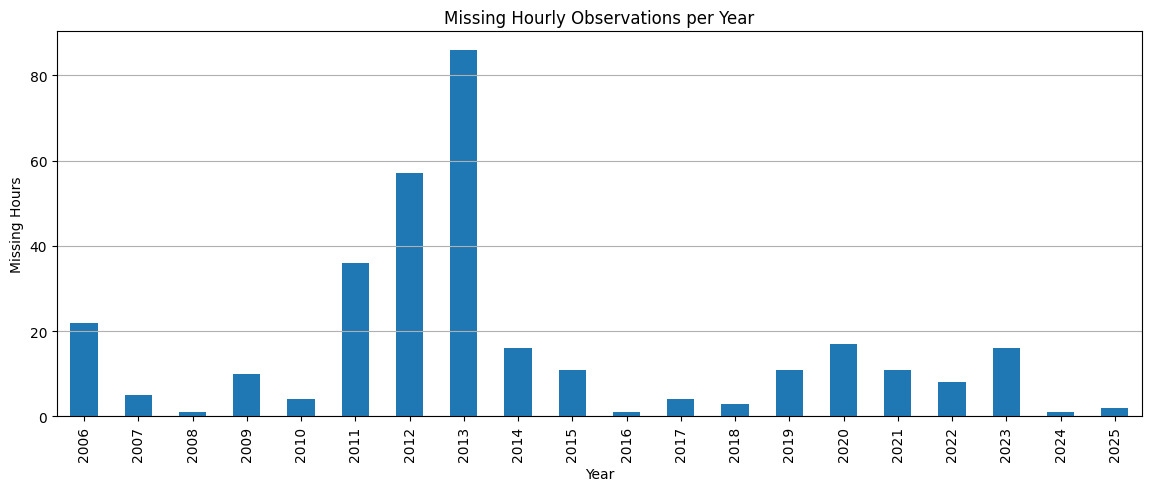

In [5]:
import calendar

# Count observations per year and compare with expected hours
year_counts = df.groupby("Year").size()

summary = pd.DataFrame({"actual": year_counts})
summary["expected"] = [8784 if calendar.isleap(y) else 8760 for y in summary.index]
summary["missing"] = summary["expected"] - summary["actual"]

display(summary)
print("Total actual:", summary["actual"].sum())
print("Total expected:", summary["expected"].sum())
print("Total missing:", summary["missing"].sum())

# Plot missing hours per year
summary["missing"].plot(
    kind="bar",
    figsize=(14, 5),
    title="Missing Hourly Observations per Year"
)
plt.xlabel("Year")
plt.ylabel("Missing Hours")
plt.grid(axis="y")
plt.show()

In [6]:
# Step 3: Find non-numeric values, convert to numbers, build datetime
temp_cols = [
    "Average temperature [°C]",
    "Maximum temperature [°C]",
    "Minimum temperature [°C]",
]

# Show which values are not numbers (before conversion)
for col in temp_cols:
    converted = pd.to_numeric(df[col], errors="coerce")
    bad_values = df.loc[converted.isna(), col].unique()
    print(col, "-> non-numeric values:", bad_values[:10])

# Convert to numbers
for col in temp_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Build a datetime column
df["datetime"] = pd.to_datetime(
    df["Year"].astype(str) + "-"
    + df["Month"].astype(str) + "-"
    + df["Day"].astype(str) + " "
    + df["Time [Local time]"],
    errors="coerce",
)

print("\nMissing values per column:")
print(df[temp_cols].isna().sum())
print("\nRows with bad datetime:", df["datetime"].isna().sum())
print("Duplicate datetime rows:", df["datetime"].duplicated().sum())

display(df[temp_cols].describe())

Average temperature [°C] -> non-numeric values: ['-']
Maximum temperature [°C] -> non-numeric values: ['-']
Minimum temperature [°C] -> non-numeric values: ['-']

Missing values per column:
Average temperature [°C]    23
Maximum temperature [°C]    32
Minimum temperature [°C]    12
dtype: int64

Rows with bad datetime: 0
Duplicate datetime rows: 20


,Average temperature [°C],Maximum temperature [°C],Minimum temperature [°C]
count,174975.000000,174966.000000,174986.000000
mean,7.103697,7.463396,6.758334
std,8.749423,8.845072,8.669890
min,-25.700000,-24.800000,-26.200000
25%,1.100000,1.300000,0.900000
50%,6.700000,7.000000,6.300000
75%,14.200000,14.600000,13.700000
max,32.600000,33.200000,31.400000


In [7]:
# Step 3b: Inspect duplicate datetime rows
dup_mask = df["datetime"].duplicated(keep=False)
dups = df.loc[dup_mask, ["datetime", "Average temperature [°C]",
                         "Maximum temperature [°C]", "Minimum temperature [°C]"]]

print("Rows involved:", len(dups))
display(dups.head(12))

print("\nDuplicates per month:")
print(df.loc[df["datetime"].duplicated(), "Month"].value_counts().sort_index())

print("\nDuplicates per year:")
print(df.loc[df["datetime"].duplicated(), "Year"].value_counts().sort_index())

Rows involved: 40


,datetime,Average temperature [°C],Maximum temperature [°C],Minimum temperature [°C]
7205,2006-10-29 03:00:00,-0.9,-0.6,-1.3
7206,2006-10-29 03:00:00,-1.1,-1.0,-1.3
15935,2007-10-28 03:00:00,7.2,7.4,7.1
15936,2007-10-28 03:00:00,7.1,7.3,7.1
24670,2008-10-26 03:00:00,9.4,9.4,9.3
24671,2008-10-26 03:00:00,9.5,9.6,9.4
33400,2009-10-25 03:00:00,3.1,3.2,3.0
33401,2009-10-25 03:00:00,3.3,3.6,3.2
42296,2010-10-31 03:00:00,8.1,8.2,8.0
42297,2010-10-31 03:00:00,8.1,8.3,8.1



Duplicates per month:
Month
10    20
Name: count, dtype: int64

Duplicates per year:
Year
2006    1
2007    1
2008    1
2009    1
2010    1
2011    1
2012    1
2013    1
2014    1
2015    1
2016    1
2017    1
2018    1
2019    1
2020    1
2021    1
2022    1
2023    1
2024    1
2025    1
Name: count, dtype: int64


In [8]:
# Step 4: Annual mean temperature
annual = df.groupby("Year")["Average temperature [°C]"].agg(["mean", "count"])
annual.columns = ["mean_temp", "valid_hours"]
annual["mean_temp"] = annual["mean_temp"].round(2)

display(annual)
print("Warmest year:", annual["mean_temp"].idxmax(), annual["mean_temp"].max())
print("Coldest year:", annual["mean_temp"].idxmin(), annual["mean_temp"].min())

,mean_temp,valid_hours
Year,,
2006,6.73,8738
2007,7.06,8755
2008,7.61,8783
2009,6.21,8750
2010,5.10,8756
2011,7.28,8724
2012,5.99,8727
2013,7.10,8674
2014,7.32,8744


Warmest year: 2020 8.66
Coldest year: 2010 5.1


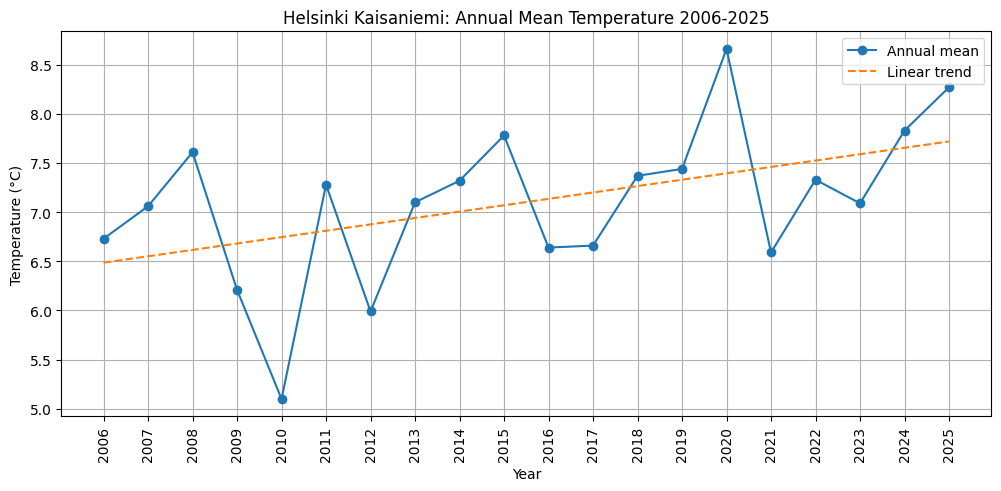

Trend per year (°C): 0.065
Trend per decade (°C): 0.65


In [9]:
# Step 5: Plot annual mean with trend line
x = annual.index.values
y = annual["mean_temp"].values

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(12, 5))
plt.plot(x, y, marker="o", label="Annual mean")
plt.plot(x, slope * x + intercept, linestyle="--", label="Linear trend")
plt.title("Helsinki Kaisaniemi: Annual Mean Temperature 2006-2025")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.xticks(x, rotation=90)
plt.grid(True)
plt.legend()
plt.show()

print("Trend per year (°C):", round(slope, 3))
print("Trend per decade (°C):", round(slope * 10, 2))

In [10]:
# Step 6: Statistical test of the trend
from scipy import stats

result = stats.linregress(annual.index.values, annual["mean_temp"].values)

print("Slope (°C/year):", round(result.slope, 4))
print("R squared:", round(result.rvalue ** 2, 3))
print("P-value:", round(result.pvalue, 4))
print("Std error of slope:", round(result.stderr, 4))

Slope (°C/year): 0.0649
R squared: 0.229
P-value: 0.0327
Std error of slope: 0.028


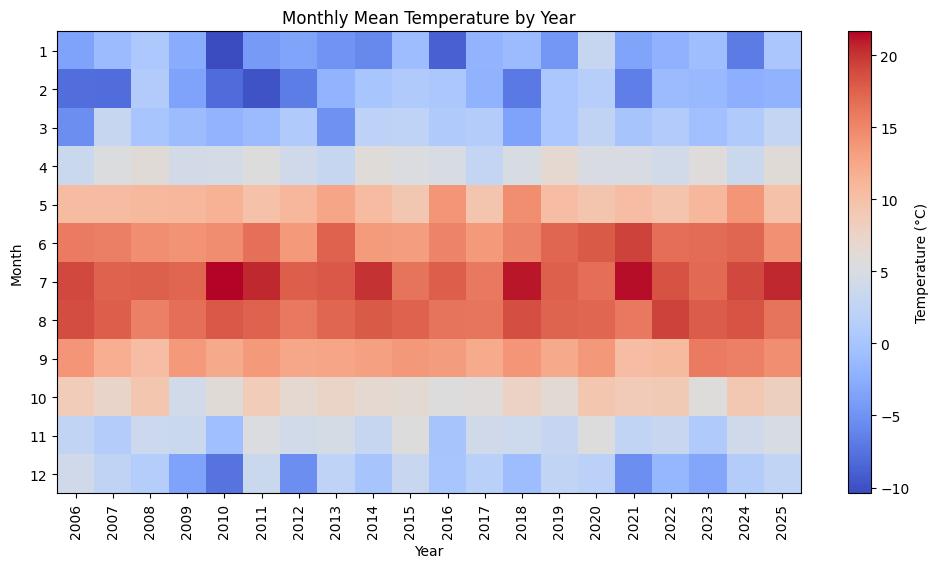

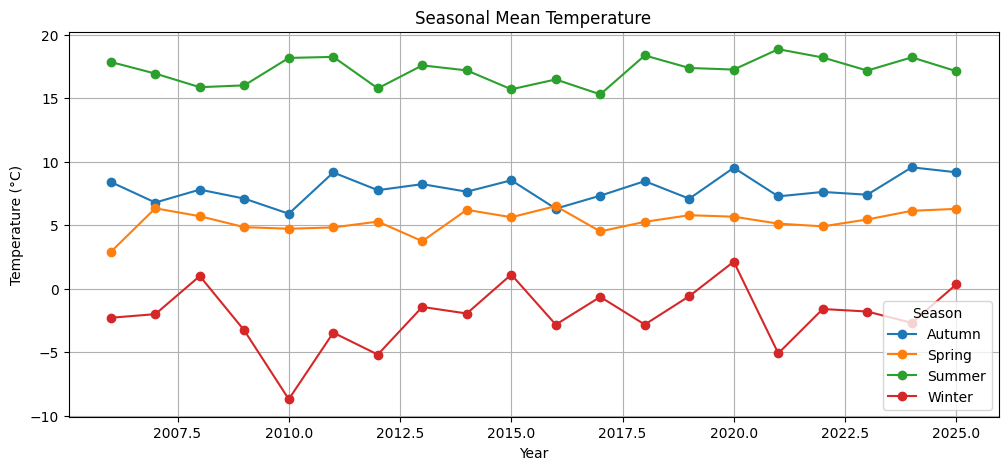

Autumn -> trend per decade (°C): 0.56 | p-value: 0.165
Spring -> trend per decade (°C): 0.58 | p-value: 0.099
Summer -> trend per decade (°C): 0.49 | p-value: 0.235
Winter -> trend per decade (°C): 1.0 | p-value: 0.307


In [11]:
# Step 7: Monthly and seasonal analysis
monthly = df.groupby(["Year", "Month"])["Average temperature [°C]"].mean().unstack()

plt.figure(figsize=(12, 6))
plt.imshow(monthly.T, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Temperature (°C)")
plt.yticks(range(12), range(1, 13))
plt.xticks(range(len(monthly.index)), monthly.index, rotation=90)
plt.title("Monthly Mean Temperature by Year")
plt.xlabel("Year")
plt.ylabel("Month")
plt.show()

season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer",
              9: "Autumn", 10: "Autumn", 11: "Autumn"}

df["Season"] = df["Month"].map(season_map)
seasonal = df.groupby(["Year", "Season"])["Average temperature [°C]"].mean().unstack()

seasonal.plot(figsize=(12, 5), marker="o", title="Seasonal Mean Temperature")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

for season in seasonal.columns:
    r = stats.linregress(seasonal.index.values, seasonal[season].values)
    print(season, "-> trend per decade (°C):", round(r.slope * 10, 2),
          "| p-value:", round(r.pvalue, 3))

In [12]:
# Step 8: Save results
out_folder = Path.cwd().parent / "Processed"
out_folder.mkdir(exist_ok=True)

annual.to_csv(out_folder / "annual_mean_temperature.csv")
monthly.to_csv(out_folder / "monthly_mean_temperature.csv")
seasonal.to_csv(out_folder / "seasonal_mean_temperature.csv")

print("Saved to folder:", out_folder.name)

Saved to folder: Processed


,year,predicted_mean,lower_95,upper_95
0,2026,7.78,6.11,9.46
1,2027,7.85,6.15,9.55
2,2028,7.91,6.19,9.64
3,2029,7.98,6.23,9.73
4,2030,8.04,6.27,9.82


Residual std (°C): 0.72
Trend change over 5 years (°C): 0.32


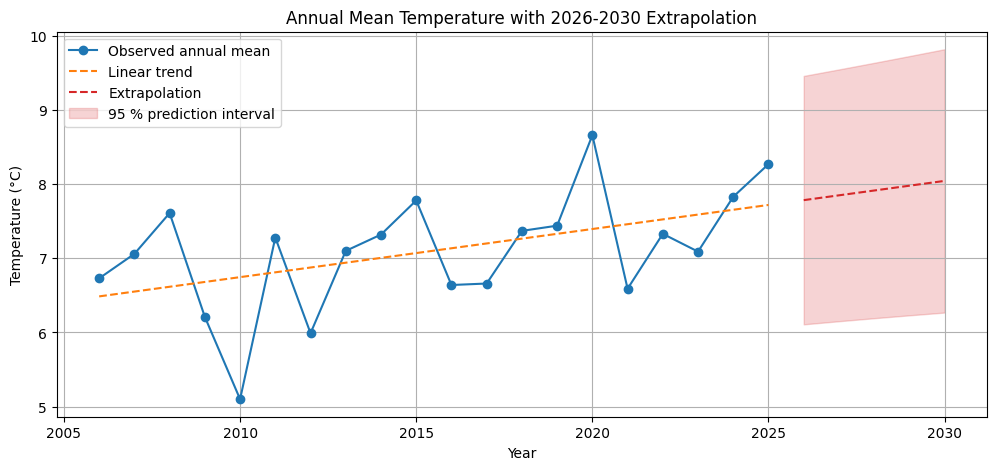

In [13]:
# Step 9: Extrapolate the linear trend with a 95 % prediction interval
x = annual.index.values.astype(float)
y = annual["mean_temp"].values
n = len(x)

res = stats.linregress(x, y)
fitted = res.intercept + res.slope * x
resid = y - fitted
s = np.sqrt(np.sum(resid ** 2) / (n - 2))
sxx = np.sum((x - x.mean()) ** 2)
t_crit = stats.t.ppf(0.975, n - 2)

future_years = np.arange(2026, 2031)
pred = res.intercept + res.slope * future_years
margin = t_crit * s * np.sqrt(1 + 1 / n + (future_years - x.mean()) ** 2 / sxx)

forecast = pd.DataFrame({
    "year": future_years,
    "predicted_mean": pred.round(2),
    "lower_95": (pred - margin).round(2),
    "upper_95": (pred + margin).round(2),
})
display(forecast)
print("Residual std (°C):", round(s, 2))
print("Trend change over 5 years (°C):", round(res.slope * 5, 2))

plt.figure(figsize=(12, 5))
plt.plot(x, y, marker="o", label="Observed annual mean")
plt.plot(x, fitted, linestyle="--", label="Linear trend")
plt.plot(future_years, pred, linestyle="--", color="tab:red", label="Extrapolation")
plt.fill_between(future_years, pred - margin, pred + margin,
                 alpha=0.2, color="tab:red", label="95 % prediction interval")
plt.title("Annual Mean Temperature with 2026-2030 Extrapolation")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.legend()
plt.show()

In [14]:
# Step 10: Robust trend tests (no normality assumption)
years = annual.index.values
temps = annual["mean_temp"].values

tau, p_mk = stats.kendalltau(years, temps)
ts = stats.theilslopes(temps, years)

print("Kendall tau:", round(tau, 3))
print("Kendall p-value:", round(p_mk, 4))
print("Theil-Sen slope (°C/year):", round(ts.slope, 4))
print("Theil-Sen slope 95 % range (°C/year):",
      round(ts.low_slope, 4), "to", round(ts.high_slope, 4))
print("Theil-Sen per decade (°C):", round(ts.slope * 10, 2))

Kendall tau: 0.347
Kendall p-value: 0.0336
Theil-Sen slope (°C/year): 0.0589
Theil-Sen slope 95 % range (°C/year): 0.0045 to 0.134
Theil-Sen per decade (°C): 0.59


In [15]:
# Step 11: Compare two decades and count extreme days
first = annual.loc[2006:2015, "mean_temp"]
last = annual.loc[2016:2025, "mean_temp"]
t_stat, p_val = stats.ttest_ind(last, first, equal_var=False)

print("Mean 2006-2015 (°C):", round(first.mean(), 2))
print("Mean 2016-2025 (°C):", round(last.mean(), 2))
print("Difference (°C):", round(last.mean() - first.mean(), 2))
print("Welch t-test p-value:", round(p_val, 3))

# Daily max and min from hourly data
daily = df.groupby(["Year", "Month", "Day"]).agg(
    tmax=("Maximum temperature [°C]", "max"),
    tmin=("Minimum temperature [°C]", "min"),
).reset_index()

extremes = daily.groupby("Year").agg(
    frost_days=("tmin", lambda s: (s < 0).sum()),
    very_cold_days=("tmin", lambda s: (s <= -20).sum()),
    warm_days=("tmax", lambda s: (s >= 25).sum()),
)
display(extremes)

for col in extremes.columns:
    r = stats.linregress(extremes.index.values, extremes[col].values)
    print(col, "-> change per decade:", round(r.slope * 10, 2),
          "| p-value:", round(r.pvalue, 3))

Mean 2006-2015 (°C): 6.82
Mean 2016-2025 (°C): 7.39
Difference (°C): 0.57
Welch t-test p-value: 0.114


,frost_days,very_cold_days,warm_days
Year,,,
2006,124,7,12
2007,102,4,11
2008,78,0,3
2009,134,0,6
2010,143,6,25
2011,100,9,16
2012,122,3,1
2013,119,2,9
2014,84,0,24


frost_days -> change per decade: -3.99 | p-value: 0.66
very_cold_days -> change per decade: -2.32 | p-value: 0.024
warm_days -> change per decade: 4.26 | p-value: 0.256


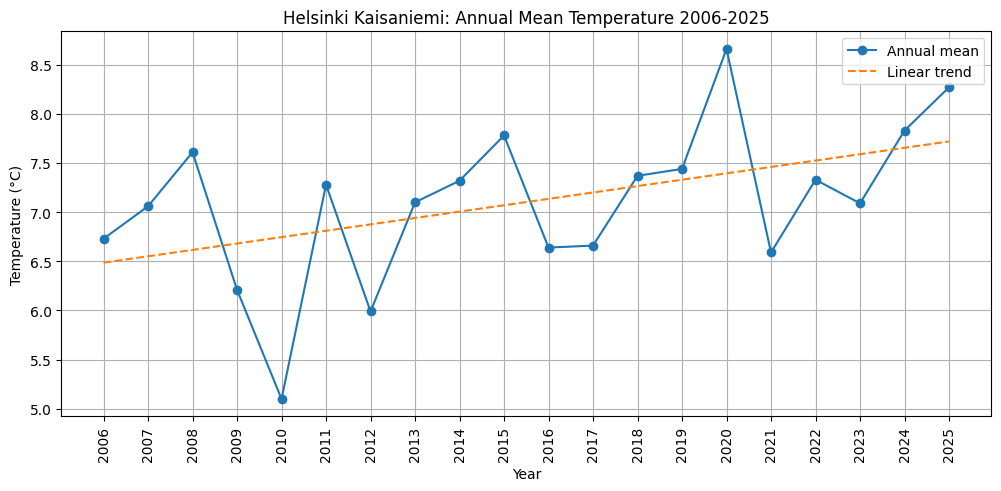

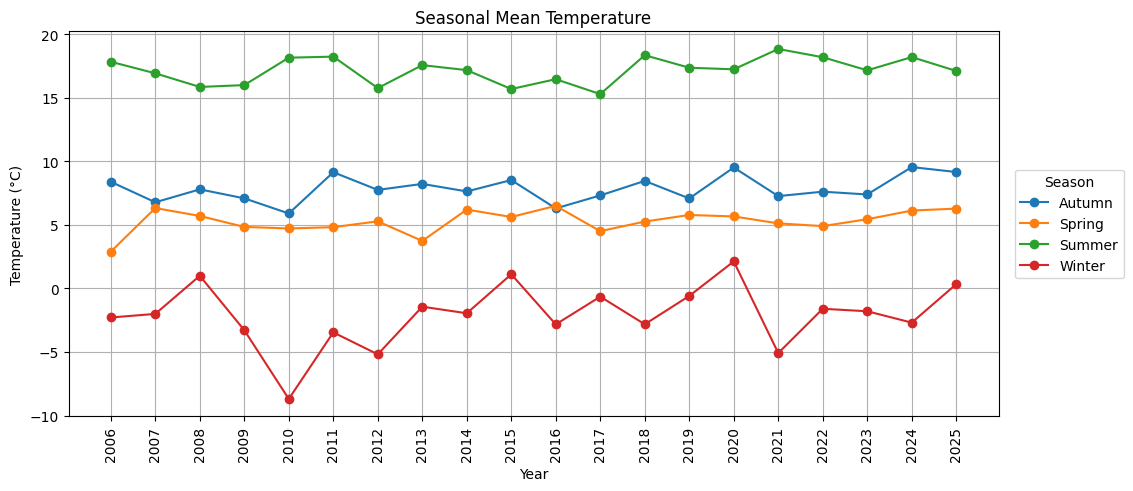

Saved figures: ['annual_mean_trend.png', 'seasonal_mean.png']


In [17]:
# Step 12: Save figures for the README
fig_folder = Path.cwd().parent.parent / "Figures"
fig_folder.mkdir(exist_ok=True)

# Figure 1: annual mean with linear trend
x = annual.index.values
y = annual["mean_temp"].values
slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(12, 5))
plt.plot(x, y, marker="o", label="Annual mean")
plt.plot(x, slope * x + intercept, linestyle="--", label="Linear trend")
plt.title("Helsinki Kaisaniemi: Annual Mean Temperature 2006-2025")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.xticks(x, rotation=90)
plt.grid(True)
plt.legend()
plt.savefig(fig_folder / "annual_mean_trend.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2: seasonal mean temperature
ax = seasonal.plot(
    figsize=(12, 5),
    marker="o",
    title="Seasonal Mean Temperature",
    xticks=seasonal.index,
)
ax.set_xticklabels(seasonal.index, rotation=90)
ax.set_xlabel("Year")
ax.set_ylabel("Temperature (°C)")
ax.grid(True)
ax.legend(title="Season", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.savefig(fig_folder / "seasonal_mean.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved figures:", [f.name for f in fig_folder.glob("*.png")])

## Conclusions

- Data: Helsinki Kaisaniemi hourly temperatures, 2006-2025 (174,998 rows).
- Data quality: 322 hours (about 0.2 %) are missing compared with a full calendar. Part of this is the spring daylight-saving jump. 20 timestamps appear twice in October (autumn clock change) and were kept. Missing temperature values: 23 (average), 32 (maximum), 12 (minimum).
- Annual mean temperature has a linear trend of +0.065 °C/year (about +0.65 °C/decade), p = 0.033, R² = 0.23.
- The trend is statistically significant at the 0.05 level, but it explains only a small part of the year-to-year variation, and 20 years is a short period.
- Seasonal trends are positive for all four seasons (0.49 to 1.0 °C/decade), but none is statistically significant on its own (p between 0.099 and 0.307).
- Warmest year: 2020 (8.66 °C). Coldest year: 2010 (5.10 °C).
- Limitation: one station, linear model only, no check of the regression assumptions.

## Future estimate and limitations

- Linear extrapolation gives an annual mean of about 8.0 °C for 2030 (95 % prediction interval 6.3 to 9.8 °C). The expected change over 5 years is only about 0.3 °C, much smaller than the year-to-year variation (residual std 0.72 °C). This is a statistical extrapolation, not a climate projection.
- Robust tests agree with the regression: Kendall tau = 0.347 (p = 0.034), Theil-Sen slope = 0.059 °C/year (95 % range 0.005 to 0.134).
- The mean of 2016-2025 (7.39 °C) is 0.57 °C higher than 2006-2015 (6.82 °C), but this difference is not statistically significant (Welch t-test p = 0.114).
- Days with minimum temperature of -20 °C or lower decreased by about 2.3 days per decade (p = 0.024). Annual counts are small, and several tests were run, so this result should be treated with caution. Frost days and warm days (max 25 °C or higher) show no significant change.
- Daily extremes were computed from hourly data with my own thresholds, not the official FMI definitions.
- Limitations: one station, only 20 years, linear model, no check of regression assumptions, no adjustment for multiple tests.